# Member 2 — Diminishing Returns & Model Training

This notebook uses `data/processed/mmm_features.csv` from Member 1. The target is `sales_revenue_lkr`. The six adstocked channel features represent carryover-adjusted media pressure; external controls cover price, promotions, competitor pressure, economic context, seasonality, and holidays. Funnel outcomes (`impressions`, `clicks`, `conversions`, `units_sold`) are intentionally excluded because they can leak information about the target or mediate advertising effects.

A Hill curve maps each channel's adstock to [0, 1], with a channel-specific midpoint set to the training-period median and slope 1.5. We compare linear versus saturated channel features with Multiple Linear Regression and Ridge, using an 80/20 chronological split. This is a small synthetic dataset (36 monthly rows); metrics are exploratory, not evidence of production forecasting performance.

In [7]:
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidates if (p / 'data/processed/mmm_features.csv').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate data/processed/mmm_features.csv from the current directory.')
sys.path.insert(0, str(PROJECT_ROOT))
from src.saturation import ADSTOCK_CHANNELS, SATURATION_SUFFIX, apply_saturation, predict_sales

DATA_PATH = PROJECT_ROOT / 'data/processed/mmm_features.csv'
OUTPUT_DIR = PROJECT_ROOT / 'outputs/mmm'
MODEL_DIR = PROJECT_ROOT / 'models'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
TARGET = 'sales_revenue_lkr'
SLOPE = 1.5
df = pd.read_csv(DATA_PATH, parse_dates=['month']).sort_values('month').reset_index(drop=True)
assert df['month'].is_monotonic_increasing and df['month'].is_unique
assert df[TARGET].notna().all()
df.shape

(36, 18)

## Feature setup and diminishing-returns transformation

All non-target numeric fields in the prepared handoff are eligible controls, except date and the six raw channel columns (the handoff already contains adstocked channel values). Midpoints are learned from the training period only to avoid using holdout information. The saturation transform is monotonic and concave around the observed range, representing diminishing marginal response rather than claiming that a causal effect has been identified.

In [5]:
channel_features = list(ADSTOCK_CHANNELS)
control_features = [
    col for col in df.select_dtypes(include='number').columns
    if col not in [TARGET, *channel_features]
]
feature_columns = [*channel_features, *control_features]
if df[feature_columns + [TARGET]].isna().any().any():
    raise ValueError('Missing values found in model features or target.')

split_at = int(len(df) * 0.8)
if split_at <= len(feature_columns) or split_at >= len(df):
    raise ValueError('Not enough observations for the chronological train/test split.')
train, test = df.iloc[:split_at].copy(), df.iloc[split_at:].copy()
midpoints = {channel: float(train[channel].median()) for channel in channel_features}
slope = SLOPE
saturated_columns = [f'{channel}{SATURATION_SUFFIX}' for channel in channel_features]

def model_matrix(frame, saturated=False, saturation_midpoints=None):
    fitted_midpoints = midpoints if saturation_midpoints is None else saturation_midpoints
    transformed = apply_saturation(frame, half_saturation=fitted_midpoints, slope=slope) if saturated else frame
    columns = [*(saturated_columns if saturated else channel_features), *control_features]
    return transformed.loc[:, columns].astype(float)

X_train_linear, X_test_linear = model_matrix(train), model_matrix(test)
X_train_saturated, X_test_saturated = model_matrix(train, True), model_matrix(test, True)
y_train, y_test = train[TARGET].astype(float), test[TARGET].astype(float)
pd.DataFrame({'channel': channel_features, 'training_median_half_saturation_lkr': [midpoints[c] for c in channel_features]})

,channel,training_median_half_saturation_lkr
0,tv_adstock_lkr,1.008792e+07
1,facebook_instagram_adstock_lkr,6.034640e+06
2,google_search_adstock_lkr,3.970793e+06
3,youtube_adstock_lkr,3.553867e+06
4,radio_adstock_lkr,2.566130e+06
5,outdoor_adstock_lkr,4.657658e+06


## Train and compare model candidates

Each model standardizes inputs inside its pipeline. Ridge regularization (`alpha=10`) reduces coefficient instability from correlated media and external variables. The final 20% is held out for reporting; model selection uses three expanding time-series validation folds from the earlier training period. Hill midpoints are recalculated within each fold to avoid leakage. R² can be negative on a short holdout and should be read alongside MAE and RMSE.

In [14]:
specs = {
    'multiple_linear_regression': (LinearRegression(), X_train_linear, X_test_linear, False),
    'ridge_regression': (Ridge(alpha=10.0), X_train_linear, X_test_linear, False),
    'saturated_multiple_linear_regression': (LinearRegression(), X_train_saturated, X_test_saturated, True),
    'saturated_ridge_regression': (Ridge(alpha=10.0), X_train_saturated, X_test_saturated, True),
}
models, rows = {}, []
for name, (regressor, X_train, X_test, saturated) in specs.items():
    estimator = make_pipeline(StandardScaler(), regressor)
    estimator.fit(X_train, y_train)
    pred_train, pred_test = estimator.predict(X_train), estimator.predict(X_test)
    models[name] = estimator
    rows.append({
        'model': name,
        'feature_variant': 'hill_saturated' if saturated else 'linear_adstock',
        'train_r2': r2_score(y_train, pred_train),
        'train_mae_lkr': mean_absolute_error(y_train, pred_train),
        'train_rmse_lkr': np.sqrt(mean_squared_error(y_train, pred_train)),
        'test_r2': r2_score(y_test, pred_test),
        'test_mae_lkr': mean_absolute_error(y_test, pred_test),
        'test_rmse_lkr': np.sqrt(mean_squared_error(y_test, pred_test)),
        'test_months': len(test),
        'test_start_month': test['month'].min().date().isoformat(),
        'test_end_month': test['month'].max().date().isoformat(),
    })
    joblib.dump({
        'estimator': estimator,
        'model_name': name,
        'feature_variant': 'hill_saturated' if saturated else 'linear_adstock',
        'feature_columns': list(X_train.columns),
        'target': TARGET,
        'saturation_midpoints': midpoints if saturated else None,
        'saturation_slope': slope if saturated else None,
        'training_end_month': train['month'].max().date().isoformat(),
    }, MODEL_DIR / f'{name}.joblib')

fold_metrics = []
time_splitter = TimeSeriesSplit(n_splits=3, test_size=3)
for fold_number, (fit_indices, validation_indices) in enumerate(time_splitter.split(train), start=1):
    fold_train = train.iloc[fit_indices]
    fold_validation = train.iloc[validation_indices]
    fold_midpoints = {channel: float(fold_train[channel].median()) for channel in channel_features}
    for name, (regressor, _, _, saturated) in specs.items():
        if saturated:
            fold_train_features = apply_saturation(fold_train, half_saturation=fold_midpoints, slope=slope)
            fold_validation_features = apply_saturation(fold_validation, half_saturation=fold_midpoints, slope=slope)
            channel_columns = saturated_columns
        else:
            fold_train_features = fold_train
            fold_validation_features = fold_validation
            channel_columns = channel_features
        fold_columns = [*channel_columns, *control_features]
        X_fit = fold_train_features.loc[:, fold_columns].astype(float)
        X_validation = fold_validation_features.loc[:, fold_columns].astype(float)
        y_fit = fold_train[TARGET].astype(float)
        y_validation = fold_validation[TARGET].astype(float)
        fold_model = make_pipeline(StandardScaler(), clone(regressor))
        fold_model.fit(X_fit, y_fit)
        fold_prediction = fold_model.predict(X_validation)
        fold_metrics.append({
            'model': name,
            'fold': fold_number,
            'validation_months': len(fold_validation),
            'cv_r2': r2_score(y_validation, fold_prediction),
            'cv_mae_lkr': mean_absolute_error(y_validation, fold_prediction),
            'cv_rmse_lkr': np.sqrt(mean_squared_error(y_validation, fold_prediction)),
        })

fold_results = pd.DataFrame(fold_metrics)
cv_summary = fold_results.groupby('model').agg(
    cv_r2_mean=('cv_r2', 'mean'),
    cv_mae_lkr_mean=('cv_mae_lkr', 'mean'),
    cv_rmse_lkr_mean=('cv_rmse_lkr', 'mean'),
    cv_rmse_lkr_std=('cv_rmse_lkr', 'std'),
).reset_index()
comparison = pd.DataFrame(rows).merge(cv_summary, on='model')
comparison = comparison.sort_values('cv_rmse_lkr_mean').reset_index(drop=True)
selected_model_name = str(comparison.loc[0, 'model'])
comparison['selected_by_time_cv'] = comparison['model'].eq(selected_model_name)

selected_path = MODEL_DIR / f'{selected_model_name}.joblib'
selected_bundle = joblib.load(selected_path)
selected_bundle.update({
    'selected_by': 'lowest mean RMSE across 3 expanding time-series validation folds',
    'cv_fold_count': int(fold_results.loc[fold_results['model'] == selected_model_name, 'fold'].nunique()),
    'cv_rmse_lkr_mean': float(comparison.loc[0, 'cv_rmse_lkr_mean']),
    'cv_rmse_lkr_std': float(comparison.loc[0, 'cv_rmse_lkr_std']),
    'holdout_start_month': test['month'].min().date().isoformat(),
    'holdout_end_month': test['month'].max().date().isoformat(),
})
joblib.dump(selected_bundle, selected_path)
smoke_prediction = predict_sales(selected_bundle, test.iloc[:1])
expected_prediction = models[selected_model_name].predict(specs[selected_model_name][2].iloc[:1])[0]
assert np.isclose(smoke_prediction.iloc[0], expected_prediction)
print('Selected candidate:', selected_model_name)
print('Prediction interface smoke test passed.')

comparison_path = OUTPUT_DIR / 'model_comparison.csv'
try:
    comparison.to_csv(comparison_path, index=False)
except PermissionError as exc:
    raise PermissionError(
        f'Cannot update {comparison_path}. Close the CSV in Excel or another editor, '
        'then rerun this cell.'
    ) from exc
comparison

Selected candidate: saturated_ridge_regression
Prediction interface smoke test passed.


,model,feature_variant,train_r2,train_mae_lkr,train_rmse_lkr,test_r2,test_mae_lkr,test_rmse_lkr,test_months,test_start_month,test_end_month,cv_r2_mean,cv_mae_lkr_mean,cv_rmse_lkr_mean,cv_rmse_lkr_std,selected_by_time_cv
0,saturated_ridge_regression,hill_saturated,0.836716,2.497696e+06,3.244754e+06,0.931603,1.145613e+06,1.325304e+06,8,2025-05-01,2025-12-01,0.630239,3.049879e+06,3.660068e+06,3.568595e+06,True
1,ridge_regression,linear_adstock,0.826960,2.565365e+06,3.340287e+06,0.883532,1.592005e+06,1.729420e+06,8,2025-05-01,2025-12-01,0.613604,3.129842e+06,3.825471e+06,3.474804e+06,False
2,saturated_multiple_linear_regression,hill_saturated,0.916197,1.957958e+06,2.324553e+06,-2.172027,7.361841e+06,9.025368e+06,8,2025-05-01,2025-12-01,-0.019198,7.480738e+06,7.802947e+06,2.165253e+06,False
3,multiple_linear_regression,linear_adstock,0.901337,2.050045e+06,2.522242e+06,-1.131254,6.316697e+06,7.397997e+06,8,2025-05-01,2025-12-01,-0.480724,8.662055e+06,9.285440e+06,1.395371e+06,False


## Saturation and modelled response curves

The first row shows each Hill transform over the observed adstock range. The second row varies one channel at a time while holding other features at training medians. Curves are conditional model responses, not causal estimates; response levels can differ because of the fitted intercept and controls.

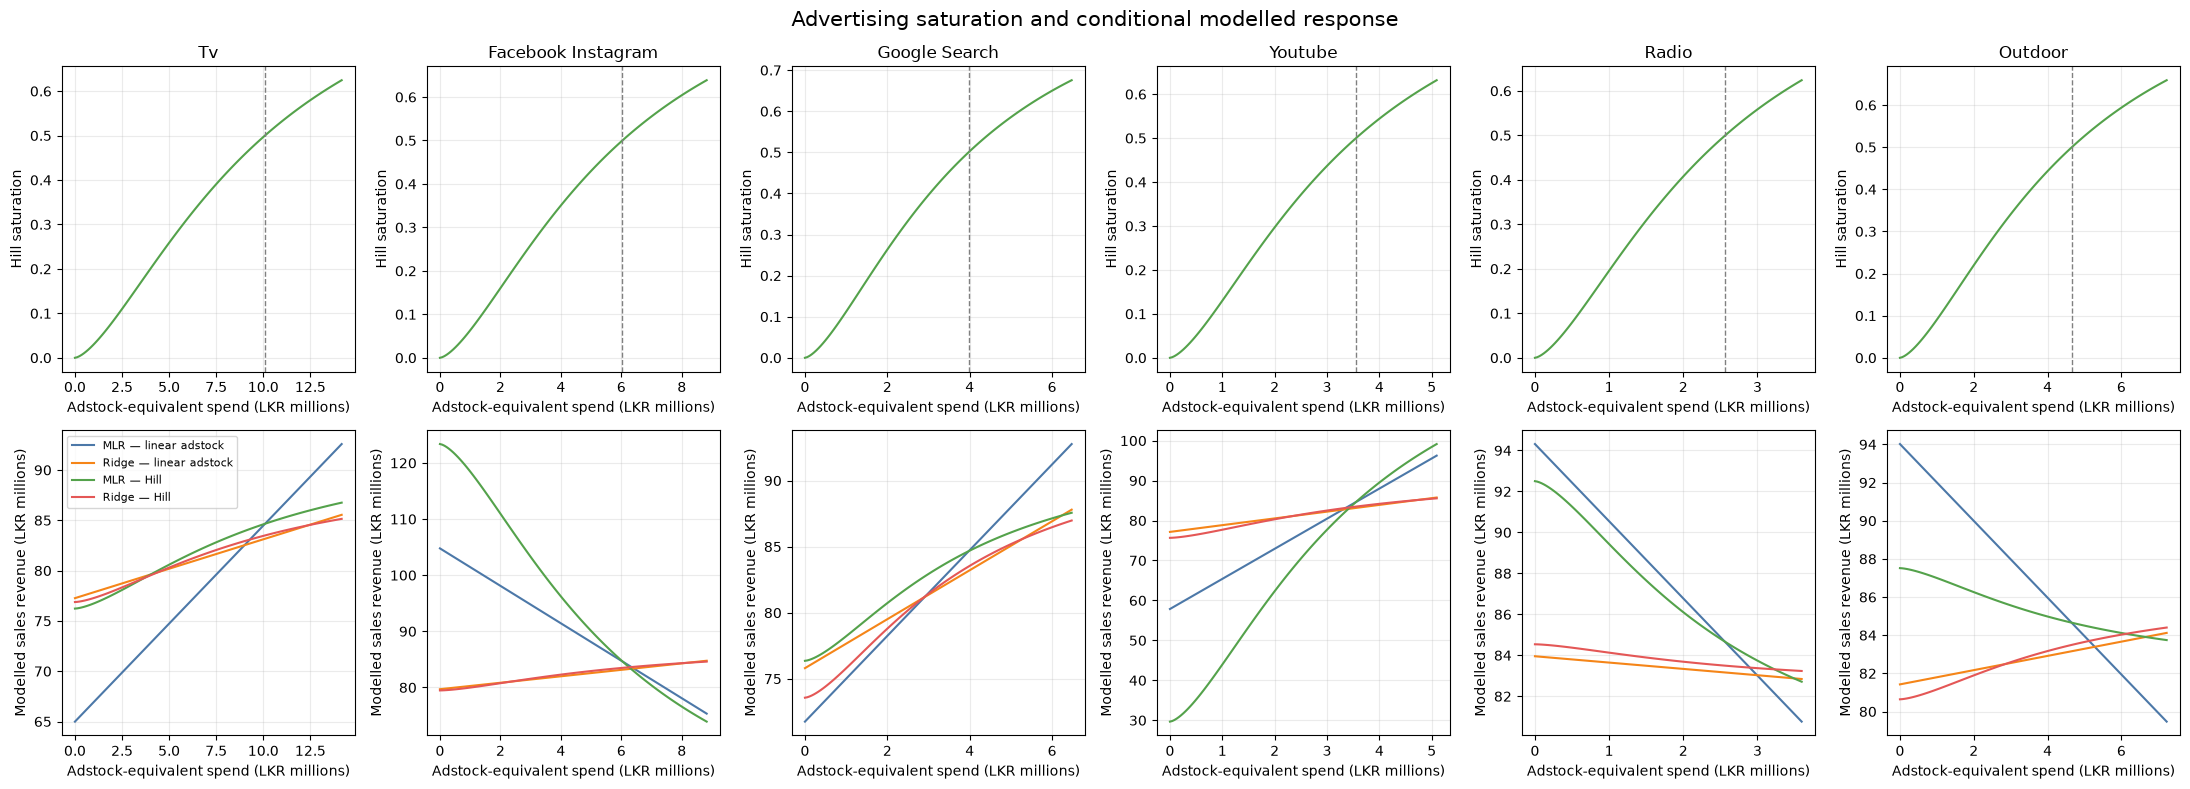

Saved: c:\Users\USER\Downloads\marketing-mix-modeling-feature-member1-adstock\marketing-mix-modeling-feature-member1-adstock\outputs\mmm\saturation_curves.png
Saved: c:\Users\USER\Downloads\marketing-mix-modeling-feature-member1-adstock\marketing-mix-modeling-feature-member1-adstock\outputs\mmm\model_comparison.csv
Saved model candidates: multiple_linear_regression.joblib, ridge_regression.joblib, saturated_multiple_linear_regression.joblib, saturated_ridge_regression.joblib


In [10]:
colors = {
    'multiple_linear_regression': '#4C78A8',
    'ridge_regression': '#F58518',
    'saturated_multiple_linear_regression': '#54A24B',
    'saturated_ridge_regression': '#E45756',
}
labels = {
    'multiple_linear_regression': 'MLR — linear adstock',
    'ridge_regression': 'Ridge — linear adstock',
    'saturated_multiple_linear_regression': 'MLR — Hill',
    'saturated_ridge_regression': 'Ridge — Hill',
}
fig, axes = plt.subplots(2, len(channel_features), figsize=(22, 8))
for index, channel in enumerate(channel_features):
    values = np.linspace(0, float(train[channel].max()) * 1.1, 120)
    axes[0, index].plot(values / 1e6, apply_saturation(
        pd.DataFrame({channel: values}), channels=[channel],
        half_saturation={channel: midpoints[channel]}, slope=slope
    )[f'{channel}{SATURATION_SUFFIX}'], color='#54A24B')
    axes[0, index].axvline(midpoints[channel] / 1e6, color='gray', linestyle='--', linewidth=1)
    axes[0, index].set_title(channel.replace('_adstock_lkr', '').replace('_', ' ').title())
    axes[0, index].set_xlabel('Adstock-equivalent spend (LKR millions)')
    axes[0, index].set_ylabel('Hill saturation')
    axes[0, index].grid(alpha=0.25)

    for name, (_, _, _, saturated) in specs.items():
        model_features = specs[name][1].columns
        curve = pd.DataFrame([specs[name][1].median().to_dict()] * len(values))
        if saturated:
            curve[f'{channel}{SATURATION_SUFFIX}'] = apply_saturation(
                pd.DataFrame({channel: values}), channels=[channel],
                half_saturation={channel: midpoints[channel]}, slope=slope
            )[f'{channel}{SATURATION_SUFFIX}'].to_numpy()
        else:
            curve[channel] = values
        prediction = models[name].predict(curve.loc[:, model_features])
        axes[1, index].plot(values / 1e6, prediction / 1e6, color=colors[name], label=labels[name])
    axes[1, index].set_xlabel('Adstock-equivalent spend (LKR millions)')
    axes[1, index].set_ylabel('Modelled sales revenue (LKR millions)')
    axes[1, index].grid(alpha=0.25)
axes[1, 0].legend(fontsize=8, loc='best')
fig.suptitle('Advertising saturation and conditional modelled response', fontsize=15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'saturation_curves.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', OUTPUT_DIR / 'saturation_curves.png')
print('Saved:', OUTPUT_DIR / 'model_comparison.csv')
print('Saved model candidates:', ', '.join(f'{name}.joblib' for name in models))

## Interpretation and limitations

- Compare test MAE/RMSE first, then test R²; the final holdout contains only a few months and is statistically unstable.
- A lower error for a saturated variant is a useful candidate signal, not proof that the Hill form is uniquely correct. Midpoints and slope are illustrative choices, not tuned causal parameters.
- The input series is synthetic. Treat channel coefficients, response curves, and forecasts as a workflow demonstration, not historical business truth.
- Model candidates are saved with feature names, training cutoff, and saturation settings in `models/`; the comparison table is `outputs/mmm/model_comparison.csv`.